**Olist Delivery Performance: 02 Root Cause Drivers of Late Delivery**

Goal: quantify what drives lateness, not to build a production predictor. Some features (like seller handling days) are only known after the order ships, which is fine for root cause analysis and would be leakage for a forecast model.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from features import add_distance, add_labels, connect, load_delivered, zip_centroids

IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

import statsmodels.formula.api as smf
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split

**1. Load and engineer features**

Distance comes from zip prefix centroids in the geolocation table (haversine, km).

In [2]:
conn = connect()
df = add_labels(add_distance(load_delivered(conn), zip_centroids(conn)))
conn.close()

df["weight_kg"] = df["total_weight_g"] / 1000
df["distance_100km"] = df["distance_km"] / 100
df["purchase_month_num"] = df["order_purchase_timestamp"].dt.month
df["purchase_dow"] = df["order_purchase_timestamp"].dt.dayofweek
df["peak_season"] = df["purchase_month_num"].isin([11, 12]).astype(int)

features = [
    "distance_100km", "weight_kg", "freight_value", "item_count", "same_state",
    "seller_handling_days", "missed_seller_deadline", "estimated_lead_days",
    "peak_season", "purchase_dow",
]
model_df = df.dropna(subset=features + ["is_late"])
model_df = model_df[(model_df["seller_handling_days"] >= 0) & (model_df["carrier_transit_days"] >= 0)]
print(f"Rows for modeling: {len(model_df):,} of {len(df):,} | late rate: {model_df['is_late'].mean():.2%}")

Rows for modeling: 94,619 of 96,470 | late rate: 6.83%


**2. Simple splits (the story in plain numbers)**

In [3]:
def late_by(col, bins=None, labels=None):
    s = pd.cut(model_df[col], bins=bins, labels=labels) if bins is not None else model_df[col]
    out = model_df.groupby(s, observed=True).agg(orders=("order_id", "count"), late_rate=("is_late", "mean"))
    out["late_rate_pct"] = (100 * out["late_rate"]).round(2)
    return out.drop(columns="late_rate")

print("Seller missed handoff deadline:")
display(late_by("missed_seller_deadline"))
print("Seller handling days:")
display(late_by("seller_handling_days", [-0.01, 1, 2, 3, 5, 7, 1000], ["0-1", "1-2", "2-3", "3-5", "5-7", "7+"]))
print("Distance (km):")
display(late_by("distance_km", [-1, 100, 500, 1000, 2000, 10000], ["<100", "100-500", "500-1000", "1000-2000", "2000+"]))
print("Same state vs cross state:")
display(late_by("same_state"))

Seller missed handoff deadline:


,orders,late_rate_pct
missed_seller_deadline,,
0,85957,5.42
1,8662,20.88


Seller handling days:


,orders,late_rate_pct
seller_handling_days,,
0-1,27881,3.84
1-2,22588,5.60
2-3,14046,5.92
3-5,16229,7.26
5-7,7366,9.87
7+,6509,21.42


Distance (km):


,orders,late_rate_pct
distance_km,,
<100,17642,4.50
100-500,36471,6.19
500-1000,25376,7.20
1000-2000,9615,9.57
2000+,5515,12.15


Same state vs cross state:


,orders,late_rate_pct
same_state,,
0,60493,8.12
1,34126,4.55


**3. Logistic regression: odds ratios**

An odds ratio above 1 means the factor raises the odds of a late delivery, holding the others constant. Freight is left out here because it overlaps heavily with distance and weight.

In [4]:
logit = smf.logit(
    "is_late ~ distance_100km + weight_kg + item_count + same_state + seller_handling_days"
    " + missed_seller_deadline + estimated_lead_days + peak_season",
    data=model_df,
).fit(disp=False)

odds = pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "ci_low": np.exp(logit.conf_int()[0]),
    "ci_high": np.exp(logit.conf_int()[1]),
    "p_value": logit.pvalues,
}).drop(index="Intercept").round(4).sort_values("odds_ratio", ascending=False)
odds.to_csv(ROOT / "data" / "processed" / "odds_ratios.csv")
print(f"Pseudo R squared: {logit.prsquared:.3f}")
odds

Pseudo R squared: 0.130


,odds_ratio,ci_low,ci_high,p_value
peak_season,1.7861,1.6670,1.9136,0.0
missed_seller_deadline,1.5431,1.4135,1.6846,0.0
seller_handling_days,1.1825,1.1727,1.1923,0.0
distance_100km,1.0793,1.0738,1.0848,0.0
weight_kg,1.0112,1.0059,1.0164,0.0
estimated_lead_days,0.8949,0.8906,0.8993,0.0
item_count,0.8199,0.7702,0.8728,0.0
same_state,0.3258,0.3012,0.3524,0.0


**4. Gradient boosting + permutation importance**

A nonlinear check on which factors matter most. Importance is measured on the test set as the drop in AUC when a feature is shuffled.

In [5]:
X = model_df[features]
y = model_df["is_late"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

gb = GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
gb.fit(X_train, y_train)
proba = gb.predict_proba(X_test)[:, 1]
print(f"Test AUC: {roc_auc_score(y_test, proba):.3f}")
print(classification_report(y_test, (proba >= 0.5).astype(int), digits=3))

Test AUC: 0.766
              precision    recall  f1-score   support

           0      0.939     0.998     0.968     22038
           1      0.806     0.116     0.202      1617

    accuracy                          0.938     23655
   macro avg      0.872     0.557     0.585     23655
weighted avg      0.930     0.938     0.915     23655



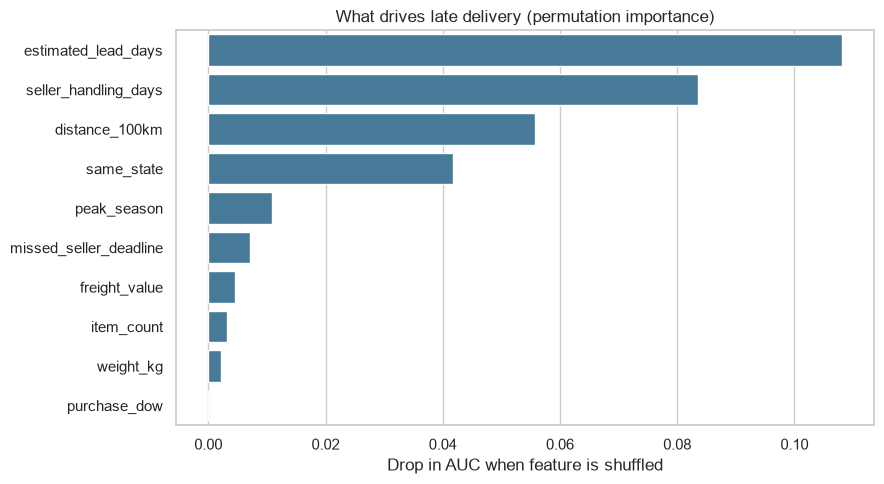

,feature,auc_drop
7,estimated_lead_days,0.108156
5,seller_handling_days,0.083560
0,distance_100km,0.055766
4,same_state,0.041768
8,peak_season,0.010814
6,missed_seller_deadline,0.007043
2,freight_value,0.004510
3,item_count,0.003225
1,weight_kg,0.002147
9,purchase_dow,-0.000073


In [6]:
perm = permutation_importance(gb, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42)
importance = (pd.DataFrame({"feature": features, "auc_drop": perm.importances_mean})
              .sort_values("auc_drop", ascending=False))
importance.to_csv(ROOT / "data" / "processed" / "feature_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=importance, x="auc_drop", y="feature", color="#3a7ca5", ax=ax)
ax.set_title("What drives late delivery (permutation importance)")
ax.set_xlabel("Drop in AUC when feature is shuffled")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMG / "feature_importance.png", dpi=150)
plt.show()
importance

**5. Findings in plain language**

Copy these numbers into the README and the resume bullet.

In [7]:
late_overall = df["is_late"].mean()
missed = model_df.groupby("missed_seller_deadline")["is_late"].mean()
missed_share = model_df["missed_seller_deadline"].mean()

state_rates = df.groupby("customer_state").agg(orders=("order_id", "count"), late=("is_late", "mean"))
state_rates = state_rates[state_rates["orders"] >= 100].sort_values("late", ascending=False)
worst_state, best_state = state_rates.index[0], state_rates.index[-1]

routes = df.groupby(["seller_state", "customer_state"]).agg(orders=("order_id", "count"), late=("is_late", "mean"))
routes = routes[routes["orders"] >= 100].sort_values("late", ascending=False)
worst_route = routes.index[0]

clean = df[(df["seller_handling_days"] >= 0) & (df["carrier_transit_days"] >= 0)]
stage = clean.groupby("is_late")[["approval_days", "seller_handling_days", "carrier_transit_days"]].mean()
extra = stage.loc[1] - stage.loc[0]
stage_label = {"approval_days": "payment approval", "seller_handling_days": "seller handling", "carrier_transit_days": "carrier transit"}
top_stage = stage_label[extra.idxmax()]
top_stage_share = extra.max() / extra.sum()

review_gap = df.loc[df["is_late"] == 0, "review_score"].mean() - df.loc[df["is_late"] == 1, "review_score"].mean()

findings = [
    f"{len(df):,} delivered orders across {df['customer_state'].nunique()} states; on-time rate {1 - late_overall:.1%}, late rate {late_overall:.1%}.",
    f"Late orders spend {extra.sum():.1f} extra days in the pipeline; the {top_stage} stage accounts for {top_stage_share:.0%} of that gap.",
    f"Orders where the seller missed the carrier handoff deadline ({missed_share:.1%} of orders) were late {missed[1]:.1%} of the time vs {missed[0]:.1%} when the deadline was met ({missed[1] / missed[0]:.1f}x).",
    f"Worst customer state: {worst_state} at {state_rates.loc[worst_state, 'late']:.1%} late vs {best_state} at {state_rates.loc[best_state, 'late']:.1%}.",
    f"Worst high-volume route: {worst_route[0]} > {worst_route[1]} at {routes.loc[worst_route, 'late']:.1%} late ({routes.loc[worst_route, 'orders']:,} orders).",
    f"Late orders average {review_gap:.2f} fewer review stars than on-time orders.",
]
for i, line in enumerate(findings, 1):
    print(f"{i}. {line}")
(ROOT / "data" / "processed" / "findings.txt").write_text("\n".join(findings))

1. 96,470 delivered orders across 27 states; on-time rate 93.2%, late rate 6.8%.
2. Late orders spend 22.9 extra days in the pipeline; the carrier transit stage accounts for 87% of that gap.
3. Orders where the seller missed the carrier handoff deadline (9.2% of orders) were late 20.9% of the time vs 5.4% when the deadline was met (3.9x).
4. Worst customer state: AL at 21.4% late vs AM at 2.8%.
5. Worst high-volume route: SP > AL at 23.9% late (255 orders).
6. Late orders average 2.02 fewer review stars than on-time orders.


511